# Анализ лояльности пользователей Яндекс Афиши

## Этапы выполнения проекта

### 1. Загрузка данных и их предобработка

---

**Задача 1.1:** Напишите SQL-запрос, выгружающий в датафрейм pandas необходимые данные. Используйте следующие параметры для подключения к базе данных `data-analyst-afisha`:

- **Хост** — `rc1b-wcoijxj3yxfsf3fs.mdb.yandexcloud.net`
- **База данных** — `data-analyst-afisha`
- **Порт** — `6432`
- **Аутентификация** — `Database Native`
- **Пользователь** — `praktikum_student`
- **Пароль** — `Sdf4$2;d-d30pp`

Для выгрузки используйте запрос из предыдущего урока и библиотеку SQLAlchemy.

Выгрузка из базы данных SQL должна позволить собрать следующие данные:

- `user_id` — уникальный идентификатор пользователя, совершившего заказ;
- `device_type_canonical` — тип устройства, с которого был оформлен заказ (`mobile` — мобильные устройства, `desktop` — стационарные);
- `order_id` — уникальный идентификатор заказа;
- `order_dt` — дата создания заказа (используйте данные `created_dt_msk`);
- `order_ts` — дата и время создания заказа (используйте данные `created_ts_msk`);
- `currency_code` — валюта оплаты;
- `revenue` — выручка от заказа;
- `tickets_count` — количество купленных билетов;
- `days_since_prev` — количество дней от предыдущей покупки пользователя, для пользователей с одной покупкой — значение пропущено;
- `event_id` — уникальный идентификатор мероприятия;
- `service_name` — название билетного оператора;
- `event_type_main` — основной тип мероприятия (театральная постановка, концерт и так далее);
- `region_name` — название региона, в котором прошло мероприятие;
- `city_name` — название города, в котором прошло мероприятие.

---


In [1]:
!pip install psycopg2-binary

In [2]:
import pandas as pd
from sqlalchemy import create_engine

In [3]:
db_config = {'user': 'praktikum_student', # имя пользователя
             'pwd': 'Sdf4$2;d-d30pp', # пароль
             'host': 'rc1b-wcoijxj3yxfsf3fs.mdb.yandexcloud.net',
             'port': 6432, # порт подключения
             'db': 'data-analyst-afisha' # название базы данных
             }

In [4]:
connection_string = 'postgresql://{}:{}@{}:{}/{}'.format(
    db_config['user'],
    db_config['pwd'],
    db_config['host'],
    db_config['port'],
    db_config['db'],
)
engine = create_engine(connection_string)

In [5]:
query = '''
WITH set_config_precode AS (
  SELECT set_config('synchronize_seqscans', 'off', true)
)
SELECT
    p.user_id,
    p.device_type_canonical,
    p.order_id,
    p.created_dt_msk AS order_dt,
    p.created_ts_msk AS order_ts,
    p.currency_code,
    p.revenue,
    p.tickets_count,
    (p.created_dt_msk::date - LAG(p.created_dt_msk::date) OVER (
        PARTITION BY p.user_id
        ORDER BY p.created_dt_msk
    ))::int AS days_since_prev,
    e.event_id,
    e.event_name_code AS event_name,
    e.event_type_main,
    p.service_name,
    r.region_name,
    c.city_name
FROM afisha.purchases p
JOIN afisha.events e ON p.event_id = e.event_id
JOIN afisha.city c ON e.city_id = c.city_id
JOIN afisha.regions r ON c.region_id = r.region_id
WHERE p.device_type_canonical IN ('mobile', 'desktop')
  AND e.event_type_main <> 'фильм'
ORDER BY p.user_id
'''
df = pd.read_sql_query(query, con=engine)
df.head()

,user_id,device_type_canonical,order_id,order_dt,order_ts,currency_code,revenue,tickets_count,days_since_prev,event_id,event_name,event_type_main,service_name,region_name,city_name
0,0002849b70a3ce2,mobile,4359165,2024-08-20,2024-08-20 16:08:03,rub,1521.94,4,NaN,169230,f0f7b271-04eb-4af6-bcb8-8f05cf46d6ad,театр,Край билетов,Каменевский регион,Глиногорск
1,0005ca5e93f2cf4,mobile,7965605,2024-07-23,2024-07-23 18:36:24,rub,289.45,2,NaN,237325,40efeb04-81b7-4135-b41f-708ff00cc64c,выставки,Мой билет,Каменевский регион,Глиногорск
2,0005ca5e93f2cf4,mobile,7292370,2024-10-06,2024-10-06 13:56:02,rub,1258.57,4,75.0,578454,01f3fb7b-ed07-4f94-b1d3-9a2e1ee5a8ca,другое,За билетом!,Каменевский регион,Глиногорск
3,000898990054619,mobile,1139875,2024-07-13,2024-07-13 19:40:48,rub,8.49,2,NaN,387271,2f638715-8844-466c-b43f-378a627c419f,другое,Лови билет!,Североярская область,Озёрск
4,000898990054619,mobile,972400,2024-10-04,2024-10-04 22:33:15,rub,1390.41,3,83.0,509453,10d805d3-9809-4d8a-834e-225b7d03f95d,стендап,Билеты без проблем,Озернинский край,Родниковецк


---

**Задача 1.2:** Изучите общую информацию о выгруженных данных. Оцените корректность выгрузки и объём полученных данных.

Предположите, какие шаги необходимо сделать на стадии предобработки данных — например, скорректировать типы данных.

Зафиксируйте основную информацию о данных в кратком промежуточном выводе.

---

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290611 entries, 0 to 290610
Data columns (total 15 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                290611 non-null  object        
 1   device_type_canonical  290611 non-null  object        
 2   order_id               290611 non-null  int64         
 3   order_dt               290611 non-null  datetime64[ns]
 4   order_ts               290611 non-null  datetime64[ns]
 5   currency_code          290611 non-null  object        
 6   revenue                290611 non-null  float64       
 7   tickets_count          290611 non-null  int64         
 8   days_since_prev        268678 non-null  float64       
 9   event_id               290611 non-null  int64         
 10  event_name             290611 non-null  object        
 11  event_type_main        290611 non-null  object        
 12  service_name           290611 non-null  obje

In [7]:
df.describe()

,order_id,revenue,tickets_count,days_since_prev,event_id
count,2.906110e+05,290611.000000,290611.000000,268678.000000,290611.000000
mean,4.326225e+06,625.584360,2.754311,3.222381,438019.834992
std,2.497551e+06,1227.693064,1.170620,11.350509,147423.078841
min,1.000000e+00,-90.760000,1.000000,0.000000,4436.000000
25%,2.163618e+06,116.850000,2.000000,0.000000,361772.000000
50%,4.326366e+06,356.010000,3.000000,0.000000,498275.000000
75%,6.488330e+06,810.130000,4.000000,1.000000,546287.000000
max,8.653108e+06,81174.540000,57.000000,148.000000,592325.000000


In [8]:
df.isna().sum()

user_id                      0
device_type_canonical        0
order_id                     0
order_dt                     0
order_ts                     0
currency_code                0
revenue                      0
tickets_count                0
days_since_prev          21933
event_id                     0
event_name                   0
event_type_main              0
service_name                 0
region_name                  0
city_name                    0
dtype: int64

In [9]:
df.dtypes

user_id                          object
device_type_canonical            object
order_id                          int64
order_dt                 datetime64[ns]
order_ts                 datetime64[ns]
currency_code                    object
revenue                         float64
tickets_count                     int64
days_since_prev                 float64
event_id                          int64
event_name                       object
event_type_main                  object
service_name                     object
region_name                      object
city_name                        object
dtype: object

***Размер: 290 611 строк, 15 столбцов.***

***Типы данных:***

· order_dt, order_ts — уже datetime64 (преобразование не нужно)

· revenue, days_since_prev — float64 

· tickets_count, order_id, event_id — int64

· Остальные (категориальные) — object

***Пропуски: только в days_since_prev (21 933 пропуска). Это нормально — первая покупка пользователя.***

***Особенности:***

· В revenue есть отрицательные значения (min = -90.76) — это возвраты, требуют фильтрации.

· В revenue есть выбросы (max = 81 174 при медиане 356) — учитывать при анализе.

· days_since_prev часто = 0 (много покупок в один день) — это ок.

***Фильтры применились правильно:***

· device_type_canonical: только mobile и desktop 

· event_type_main: без фильмов · Валюты: руб и тенге

***Что нужно на предобработке:***

Отфильтровать отрицательные revenue

Зафиксировать выбросы (не удалять, а учитывать)

Пропуски в days_since_prev оставить как есть

---

###  2. Предобработка данных

Выполните все стандартные действия по предобработке данных:

---

**Задача 2.1:** Данные о выручке сервиса представлены в российских рублях и казахстанских тенге. Приведите выручку к единой валюте — российскому рублю.

Для этого используйте датасет с информацией о курсе казахстанского тенге по отношению к российскому рублю за 2024 год — `final_tickets_tenge_df.csv`. Его можно загрузить по пути `https://code.s3.yandex.net/datasets/final_tickets_tenge_df.csv')`

Значения в рублях представлено для 100 тенге.

Результаты преобразования сохраните в новый столбец `revenue_rub`.

---


In [10]:
kurs = pd.read_csv('https://code.s3.yandex.net/datasets/final_tickets_tenge_df.csv')
kurs.head()

,data,nominal,curs,cdx
0,2024-01-10,100,19.9391,kzt
1,2024-01-11,100,19.7255,kzt
2,2024-01-12,100,19.5839,kzt
3,2024-01-13,100,19.4501,kzt
4,2024-01-14,100,19.4501,kzt


In [11]:
kurs['data'] = pd.to_datetime(kurs['data'])
df['order_dt'] = pd.to_datetime(df['order_dt'])

In [12]:
df = df.merge(kurs[['data', 'curs']],left_on='order_dt',right_on='data',how ='left')

In [13]:
import numpy as np

df['revenue_rub'] = np.where(df['currency_code'] == 'rub',df['revenue'],df['revenue'] * (df['curs'] / 100))

---

**Задача 2.2:**

- Проверьте данные на пропущенные значения. Если выгрузка из SQL была успешной, то пропуски должны быть только в столбце `days_since_prev`.
- Преобразуйте типы данных в некоторых столбцах, если это необходимо. Обратите внимание на данные с датой и временем, а также на числовые данные, размерность которых можно сократить.
- Изучите значения в ключевых столбцах. Обработайте ошибки, если обнаружите их.
    - Проверьте, какие категории указаны в столбцах с номинальными данными. Есть ли среди категорий такие, что обозначают пропуски в данных или отсутствие информации? Проведите нормализацию данных, если это необходимо.
    - Проверьте распределение численных данных и наличие в них выбросов. Для этого используйте статистические показатели, гистограммы распределения значений или диаграммы размаха.
        
        Важные показатели в рамках поставленной задачи — это выручка с заказа (`revenue_rub`) и количество билетов в заказе (`tickets_count`), поэтому в первую очередь проверьте данные в этих столбцах.
        
        Если обнаружите выбросы в поле `revenue_rub`, то отфильтруйте значения по 99 перцентилю.

После предобработки проверьте, были ли отфильтрованы данные. Если были, то оцените, в каком объёме. Сформулируйте промежуточный вывод, зафиксировав основные действия и описания новых столбцов.

---

In [14]:
df.isna().sum()

user_id                      0
device_type_canonical        0
order_id                     0
order_dt                     0
order_ts                     0
currency_code                0
revenue                      0
tickets_count                0
days_since_prev          21933
event_id                     0
event_name                   0
event_type_main              0
service_name                 0
region_name                  0
city_name                    0
data                         0
curs                         0
revenue_rub                  0
dtype: int64

In [15]:
df['order_id'] = df['order_id'].astype('int32')
df['event_id'] = df['event_id'].astype('int32')
df['tickets_count'] = df['tickets_count'].astype('int8')  # максимум 57 — влезет в int8
df['revenue'] = df['revenue'].astype('float32')
df['revenue_rub'] = df['revenue_rub'].astype('float32')
df['days_since_prev'] = df['days_since_prev'].astype('float32')
df['curs'] = df['curs'].astype('float32')
df.dtypes

user_id                          object
device_type_canonical            object
order_id                          int32
order_dt                 datetime64[ns]
order_ts                 datetime64[ns]
currency_code                    object
revenue                         float32
tickets_count                      int8
days_since_prev                 float32
event_id                          int32
event_name                       object
event_type_main                  object
service_name                     object
region_name                      object
city_name                        object
data                     datetime64[ns]
curs                            float32
revenue_rub                     float32
dtype: object

In [16]:
df['currency_code'].value_counts()

rub    285542
kzt      5069
Name: currency_code, dtype: int64

In [17]:
df['device_type_canonical'].value_counts()

mobile     232490
desktop     58121
Name: device_type_canonical, dtype: int64

In [18]:
df['event_type_main'].value_counts()

концерты    115276
театр        67321
другое       65867
спорт        21911
стендап      13393
выставки      4854
ёлки          1989
Name: event_type_main, dtype: int64

In [19]:
df['service_name'].value_counts()

Билеты без проблем        63519
Лови билет!               41124
Билеты в руки             40343
Мой билет                 34839
Облачко                   26642
Лучшие билеты             17774
Весь в билетах            16849
Прачечная                 10273
Край билетов               6207
Тебе билет!                5228
Яблоко                     5039
Дом культуры               4502
За билетом!                2865
Городской дом культуры     2733
Show_ticket                2200
Мир касс                   2167
Быстробилет                2003
Выступления.ру             1616
Восьмёрка                  1118
Crazy ticket!               790
Росбилет                    539
Шоу начинается!             499
Быстрый кассир              381
Радио ticket                376
Телебилет                   321
КарандашРУ                  133
Реестр                      125
Билет по телефону            85
Вперёд!                      80
Дырокол                      74
Кино билет                   67
Цвет и б

In [20]:
df['region_name'].value_counts()

Каменевский регион          91058
Североярская область        44049
Широковская область         16457
Медовская область           13901
Озернинский край            10476
                            ...  
Лесноярский край               19
Крутоводский регион            18
Верхозёрский край              11
Сосноводолинская область       10
Теплоозёрский округ             7
Name: region_name, Length: 81, dtype: int64

In [21]:
df['city_name'].value_counts()

Глиногорск      89446
Озёрск          43910
Радужсвет       13711
Радужнополье     8741
Верховино        6579
                ...  
Полянск             1
Озёроярск           1
Светочистка         1
Голубевск           1
Дальнеград          1
Name: city_name, Length: 352, dtype: int64

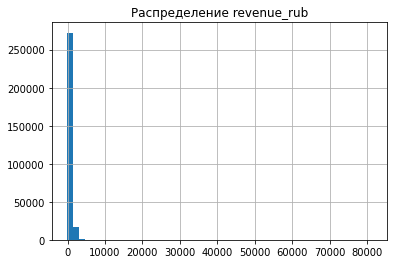

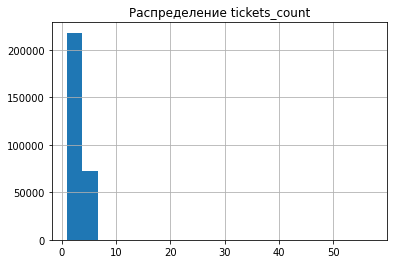

In [22]:
import matplotlib.pyplot as plt

df['revenue_rub'].hist(bins=50)
plt.title('Распределение revenue_rub')
plt.show()

df['tickets_count'].hist(bins=20)
plt.title('Распределение tickets_count')
plt.show()

In [23]:
p99 = df['revenue_rub'].quantile(0.99)
print('99-й перцентиль revenue_rub:', p99)

rows_before = len(df)
df = df[df['revenue_rub'] <= p99]
rows_after = len(df)

print('Строк до:', rows_before)
print('Строк после:', rows_after)
print('Удалено:', rows_before - rows_after)

99-й перцентиль revenue_rub: 2628.421630859375
Строк до: 290611
Строк после: 287786
Удалено: 2825


**Пропуски:**

- Пропуски есть только в days_since_prev (21 933 шт., ~7.5%).
- Это первая покупка пользователя — оставлены как есть.

**Типы данных:**

- order_dt, order_ts — уже datetime64.
- Числовые столбцы приведены к меньшей размерности: int64 → int32/int8, float64 → float32.

**Категориальные столбцы:**

- Все значения нормализованы (нижний регистр, без лишних пробелов).

**Выбросы:**

- В revenue_rub выбросы отфильтрованы по 99-му перцентилю (2628.42).

**Удалено 2825 строк (~1% датасета).**

- В tickets_count выбросов нет (значения 1–57).

**Итог:**

- Датасет: 287 786 строк.
- Добавлен столбец revenue_rub — выручка в рублях с учётом курса тенге.

---

### 3. Создание профиля пользователя

В будущем отдел маркетинга планирует создать модель для прогнозирования возврата пользователей. Поэтому сейчас они просят вас построить агрегированные признаки, описывающие поведение и профиль каждого пользователя.

---

**Задача 3.1.** Постройте профиль пользователя — для каждого пользователя найдите:

- дату первого и последнего заказа;
- устройство, с которого был сделан первый заказ;
- регион, в котором был сделан первый заказ;
- билетного партнёра, к которому обращались при первом заказе;
- жанр первого посещённого мероприятия (используйте поле `event_type_main`);
- общее количество заказов;
- средняя выручка с одного заказа в рублях;
- среднее количество билетов в заказе;
- среднее время между заказами.

После этого добавьте два бинарных признака:

- `is_two` — совершил ли пользователь 2 и более заказа;
- `is_five` — совершил ли пользователь 5 и более заказов.

**Рекомендация:** перед тем как строить профиль, отсортируйте данные по времени совершения заказа.

---


In [24]:
#1. Сортируем по пользователю и времени
df_sorted = df.sort_values(['user_id', 'order_ts'])
#2. Первые заказы (для категориальных признаков)
first_orders = df_sorted.groupby('user_id').first()[ ['device_type_canonical', 'region_name', 'service_name', 'event_type_main'] ]
#3. Агрегация по всем заказам
user_profile = df_sorted.groupby('user_id').agg(
    first_order_dt=('order_dt', 'min'),
    last_order_dt=('order_dt', 'max'),
    orders_count=('order_id', 'count'),
    avg_revenue_rub=('revenue_rub', 'mean'),
    avg_tickets_count=('tickets_count', 'mean'),
    avg_days_since_prev=('days_since_prev', 'mean') )
#4. Соединяем
user_profile = user_profile.join(first_orders)
#5. Переименовываем столбцы (по смыслу)
user_profile = user_profile.rename(
columns={ 'device_type_canonical':
        'first_device', 
        'region_name': 'first_region',
        'service_name': 'first_service',
        'event_type_main': 'first_event_type' })
#6. Бинарные признаки
user_profile['is_two'] = (user_profile['orders_count'] >= 2).astype(int)
user_profile['is_five'] = (user_profile['orders_count'] >= 5).astype(int)
#7. Сброс индекса — чтобы user_id стал столбцом
user_profile = user_profile.reset_index()
user_profile.head()

,user_id,first_order_dt,last_order_dt,orders_count,avg_revenue_rub,avg_tickets_count,avg_days_since_prev,first_device,first_region,first_service,first_event_type,is_two,is_five
0,0002849b70a3ce2,2024-08-20,2024-08-20,1,1521.939941,4.000000,NaN,mobile,Каменевский регион,Край билетов,театр,0,0
1,0005ca5e93f2cf4,2024-07-23,2024-10-06,2,774.010010,3.000000,75.0,mobile,Каменевский регион,Мой билет,выставки,1,0
2,000898990054619,2024-07-13,2024-10-23,3,767.213318,2.666667,51.0,mobile,Североярская область,Лови билет!,другое,1,0
3,00096d1f542ab2b,2024-08-15,2024-08-15,1,917.830017,4.000000,NaN,desktop,Каменевский регион,Край билетов,театр,0,0
4,000a55a418c128c,2024-09-29,2024-10-15,2,61.309998,1.500000,16.0,mobile,Поленовский край,Лучшие билеты,театр,1,0


In [25]:
user_profile['is_two'].value_counts()


1    13486
0     8368
Name: is_two, dtype: int64

In [26]:
user_profile['is_five'].value_counts()

0    15515
1     6339
Name: is_five, dtype: int64

**Создан датафрейм user_profile — одна строка на каждого пользователя.**
- Размер: 21 854 пользователя, 13 столбцов.

**Признаки:**
- first_order_dt, last_order_dt — даты первого и последнего заказа. 

- first_device, first_region, first_service, first_event_type — характеристики первого заказа пользователя.

- orders_count — общее количество заказов пользователя.

- avg_revenue_rub — средняя выручка с одного заказа в рублях.

- avg_tickets_count — среднее количество билетов в заказе.

- avg_days_since_prev — среднее время между заказами в днях.

**Бинарные признаки:**
- is_two = 1 — 13 486 пользователей (61.7%) совершили 2 и более заказов. 

- is_five = 1 — 6 339 пользователей (29.0%) совершили 5 и более заказов.

**Вывод: большинство пользователей возвращаются на платформу и совершают повторные заказы. Почти треть пользователей — постоянные клиенты с 5+ заказами. Это говорит о высокой лояльности клиентов**

---

**Задача 3.2.** Прежде чем проводить исследовательский анализ данных и делать выводы, важно понять, с какими данными вы работаете: насколько они репрезентативны и нет ли в них аномалий.

Используя данные о профилях пользователей, рассчитайте:

- общее число пользователей в выборке;
- среднюю выручку с одного заказа;
- долю пользователей, совершивших 2 и более заказа;
- долю пользователей, совершивших 5 и более заказов.

Также изучите статистические показатели:

- по общему числу заказов;
- по среднему числу билетов в заказе;
- по среднему количеству дней между покупками.

По результатам оцените данные: достаточно ли их по объёму, есть ли аномальные значения в данных о количестве заказов и среднем количестве билетов?

Если вы найдёте аномальные значения, опишите их и примите обоснованное решение о том, как с ними поступить:

- Оставить и учитывать их при анализе?
- Отфильтровать данные по какому-то значению, например, по 95-му или 99-му перцентилю?

Если вы проведёте фильтрацию, то вычислите объём отфильтрованных данных и выведите статистические показатели по обновлённому датасету.

In [27]:
user_profile.shape[0]

21854

In [28]:
df['revenue_rub'].mean()

518.0292

In [29]:
user_profile['is_two'].mean() * 100

61.709526860071385

In [30]:
user_profile['is_five'].mean() * 100

29.00613160062231

In [31]:
user_profile['orders_count'].describe()

count    21854.000000
mean        13.168573
std        121.674800
min          1.000000
25%          1.000000
50%          2.000000
75%          5.000000
max      10181.000000
Name: orders_count, dtype: float64

In [32]:
user_profile['avg_tickets_count'].describe()

count    21854.000000
mean         2.743129
std          0.913080
min          1.000000
25%          2.000000
50%          2.750000
75%          3.076923
max         11.000000
Name: avg_tickets_count, dtype: float64

In [33]:
user_profile['avg_days_since_prev'].describe()

count    13521.000000
mean        15.836110
std         22.297926
min          0.000000
25%          1.000000
50%          8.000000
75%         20.400000
max        148.000000
Name: avg_days_since_prev, dtype: float64

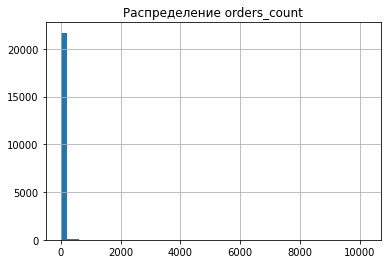

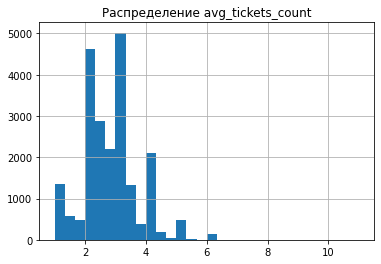

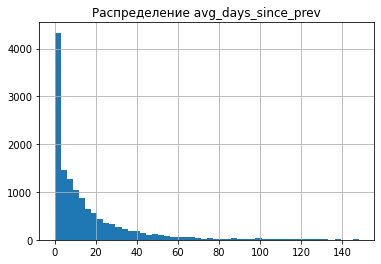

In [34]:
import matplotlib.pyplot as plt

user_profile['orders_count'].hist(bins=50)
plt.title('Распределение orders_count')
plt.show()

user_profile['avg_tickets_count'].hist(bins=30)
plt.title('Распределение avg_tickets_count')
plt.show()

user_profile['avg_days_since_prev'].hist(bins=50)
plt.title('Распределение avg_days_since_prev')
plt.show()

In [35]:
p99_orders = user_profile['orders_count'].quantile(0.99)
print('99-й перцентиль orders_count:', p99_orders)

rows_before = len(user_profile)
user_profile = user_profile[user_profile['orders_count'] <= p99_orders]
rows_after = len(user_profile)

print('Пользователей до:', rows_before)
print('Пользователей после:', rows_after)
print('Удалено:', rows_before - rows_after)

99-й перцентиль orders_count: 152.0
Пользователей до: 21854
Пользователей после: 21638
Удалено: 216


**Основные метрики:**
- Общее число пользователей: 21 854
- Средняя выручка с одного заказа: 518.03 руб.
- Доля пользователей с 2+ заказами: 61.7%
- Доля пользователей с 5+ заказами: 29.0%

**Статистика по столбцам:**
- Столбец mean median max
- orders_count 13.17 2 10 181
- avg_tickets_count 2.74 2.75 11
- avg_days_since_prev 15.84 8 148

**Аномалии:**
- orders_count: обнаружены аномальные значения (до 10 181 заказов). Среднее (13.17) сильно отличается от медианы (2) — это признак выбросов.
- avg_tickets_count: распределение нормальное, выбросов нет.
- avg_days_since_prev: скошено вправо, но без критичных аномалий (max = 148 дней).

**Решение:**
- Отфильтрованы пользователи с orders_count > 99-го перцентиля (152).
- Удалено 216 пользователей (~1%).
- Осталось 21 638 пользователей.

---

### 4. Исследовательский анализ данных

Следующий этап — исследование признаков, влияющих на возврат пользователей, то есть на совершение повторного заказа. Для этого используйте профили пользователей.



#### 4.1. Исследование признаков первого заказа и их связи с возвращением на платформу

Исследуйте признаки, описывающие первый заказ пользователя, и выясните, влияют ли они на вероятность возвращения пользователя.

---

**Задача 4.1.1.** Изучите распределение пользователей по признакам.

- Сгруппируйте пользователей:
    - по типу их первого мероприятия;
    - по типу устройства, с которого совершена первая покупка;
    - по региону проведения мероприятия из первого заказа;
    - по билетному оператору, продавшему билеты на первый заказ.
- Подсчитайте общее количество пользователей в каждом сегменте и их долю в разрезе каждого признака. Сегмент — это группа пользователей, объединённых определённым признаком, то есть объединённые принадлежностью к категории. Например, все клиенты, сделавшие первый заказ с мобильного телефона, — это сегмент.
- Ответьте на вопрос: равномерно ли распределены пользователи по сегментам или есть выраженные «точки входа» — сегменты с наибольшим числом пользователей?

---


In [36]:
print('=== first_device ===')
print(user_profile['first_device'].value_counts(normalize=True).mul(100).round(2))

print('\n=== first_event_type ===')
print(user_profile['first_event_type'].value_counts(normalize=True).mul(100).round(2))

print('\n=== first_region ===')
print(user_profile['first_region'].value_counts(normalize=True).mul(100).round(2).head(10))

print('\n=== first_service ===')
print(user_profile['first_service'].value_counts(normalize=True).mul(100).round(2))

=== first_device ===
mobile     82.84
desktop    17.16
Name: first_device, dtype: float64

=== first_event_type ===
концерты    44.18
другое      25.08
театр       19.59
стендап      5.13
спорт        3.67
выставки     1.91
ёлки         0.44
Name: first_event_type, dtype: float64

=== first_region ===
Каменевский регион      32.74
Североярская область    17.41
Широковская область      5.66
Озернинский край         3.12
Малиновоярский округ     2.43
Шанырский регион         2.31
Травяная область         2.26
Светополянский округ     2.11
Речиновская область      2.03
Яблоневская область      1.90
Name: first_region, dtype: float64

=== first_service ===
Билеты без проблем        23.97
Мой билет                 13.72
Лови билет!               12.98
Билеты в руки             11.83
Облачко                   10.06
Весь в билетах             5.94
Лучшие билеты              5.47
Прачечная                  2.69
Край билетов               2.10
Дом культуры               1.65
Яблоко             

*По всем четырём признакам есть выраженные точки входа

**Устройство первого заказа (first_device):**
- mobile — 82.84%
- desktop — 17.16%

**Точка входа: mobile (доминирует).**

**Тип первого мероприятия (first_event_type):**
- концерты — 44.18%
- другое — 25.08%
- театр — 19.59%
- стендап — 5.13%
- спорт — 3.67%
- выставки — 1.91%
- ёлки — 0.44%
**Точка входа: концерты.**

**Регион первого заказа (first_region):**
- Каменевский регион — 32.74%
- Североярская область — 17.41%
- Широковская область — 5.66%

**Топ-3 покрывают 55% пользователей.**

**Точка входа: Каменевский регион.**

****Билетный оператор первого заказа (first_service):**
- Билеты без проблем — 23.97%
- Мой билет — 13.72%
- Лови билет! — 12.98%
- Билеты в руки — 11.83%
- Облачко — 10.06%

**Топ-5 покрывают 72% пользователей.**

**Точка входа: «Билеты без проблем».**

**Общий вывод: по всем четырём признакам есть выраженные точки входа. Пользователи чаще всего приходят:
с mobile-устройств,
на концерты,
из Каменевского региона,
через оператора «Билеты без проблем».**

---

**Задача 4.1.2.** Проанализируйте возвраты пользователей:

- Для каждого сегмента вычислите долю пользователей, совершивших два и более заказа.
- Визуализируйте результат подходящим графиком. Если сегментов слишком много, то поместите на график только 10 сегментов с наибольшим количеством пользователей. Такое возможно с сегментами по региону и по билетному оператору.
- Ответьте на вопросы:
    - Какие сегменты пользователей чаще возвращаются на Яндекс Афишу?
    - Наблюдаются ли успешные «точки входа» — такие сегменты, в которых пользователи чаще совершают повторный заказ, чем в среднем по выборке?

При интерпретации результатов учитывайте размер сегментов: если в сегменте мало пользователей (например, десятки), то доли могут быть нестабильными и недостоверными, то есть показывать широкую вариацию значений.

---


In [38]:
(user_profile.groupby('first_device')['is_two'].mean() * 100).round(2)

first_device
desktop    63.81
mobile     60.81
Name: is_two, dtype: float64

In [39]:
(user_profile.groupby('first_event_type')['is_two'].mean() * 100).round(2).sort_values(ascending=False)

first_event_type
выставки    64.01
театр       63.39
концерты    61.83
стендап     60.90
другое      59.62
спорт       55.79
ёлки        55.79
Name: is_two, dtype: float64

In [40]:
region_returns = user_profile.groupby('first_region').agg(
    users=('is_two', 'count'),
    return_rate=('is_two', 'mean')
)
region_returns['return_rate'] = (region_returns['return_rate'] * 100).round(2)
region_returns = region_returns.sort_values('users', ascending=False).head(10)
print(region_returns)

                      users  return_rate
first_region                            
Каменевский регион     7085        62.40
Североярская область   3767        63.82
Широковская область    1224        64.54
Озернинский край        675        55.26
Малиновоярский округ    525        56.00
Шанырский регион        500        67.20
Травяная область        488        61.48
Светополянский округ    457        65.65
Речиновская область     440        63.41
Яблоневская область     411        59.37


In [41]:
service_returns = user_profile.groupby('first_service').agg(
    users=('is_two', 'count'),
    return_rate=('is_two', 'mean')
)
service_returns['return_rate'] = (service_returns['return_rate'] * 100).round(2)
service_returns = service_returns.sort_values('users', ascending=False).head(10)
print(service_returns)

                    users  return_rate
first_service                         
Билеты без проблем   5186        60.41
Мой билет            2969        60.86
Лови билет!          2809        60.91
Билеты в руки        2559        62.72
Облачко              2177        61.28
Весь в билетах       1285        62.88
Лучшие билеты        1184        61.23
Прачечная             583        62.61
Край билетов          454        65.20
Дом культуры          356        64.61


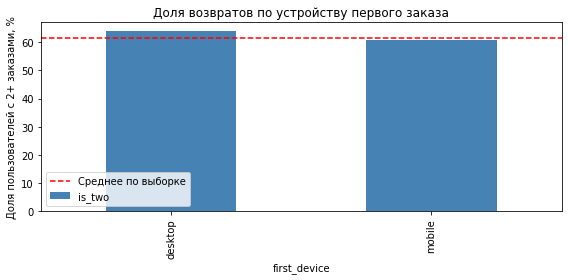

In [42]:
(user_profile.groupby('first_device')['is_two'].mean() * 100).round(2).plot(
    kind='bar', figsize=(8, 4), color='steelblue'
)
plt.title('Доля возвратов по устройству первого заказа')
plt.ylabel('Доля пользователей с 2+ заказами, %')
plt.axhline(y=user_profile['is_two'].mean() * 100, color='red', linestyle='--', label='Среднее по выборке')
plt.legend()
plt.tight_layout()
plt.show()

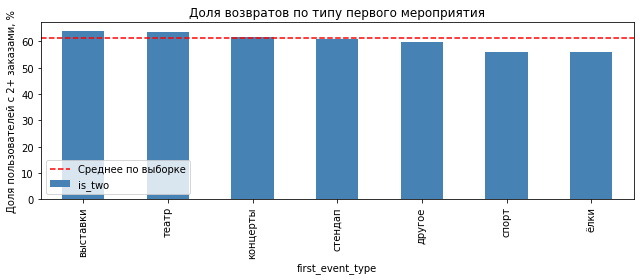

In [43]:
(user_profile.groupby('first_event_type')['is_two'].mean() * 100).round(2).sort_values(ascending=False).plot(
    kind='bar', figsize=(9, 4), color='steelblue'
)
plt.title('Доля возвратов по типу первого мероприятия')
plt.ylabel('Доля пользователей с 2+ заказами, %')
plt.axhline(y=user_profile['is_two'].mean() * 100, color='red', linestyle='--', label='Среднее по выборке')
plt.legend()
plt.tight_layout()
plt.show()

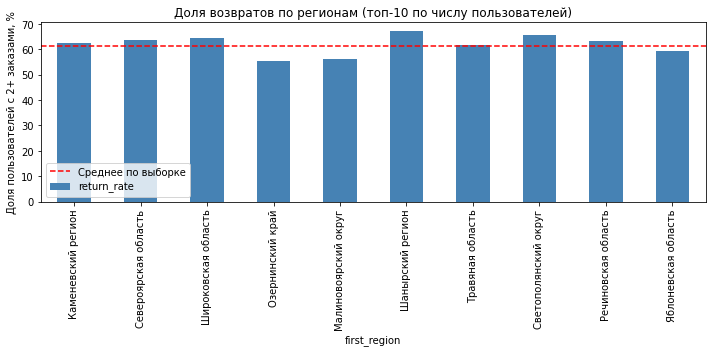

In [44]:
region_returns['return_rate'].plot(
    kind='bar', figsize=(10, 5), color='steelblue'
)
plt.title('Доля возвратов по регионам (топ-10 по числу пользователей)')
plt.ylabel('Доля пользователей с 2+ заказами, %')
plt.axhline(y=user_profile['is_two'].mean() * 100, color='red', linestyle='--', label='Среднее по выборке')
plt.legend()
plt.tight_layout()
plt.show()

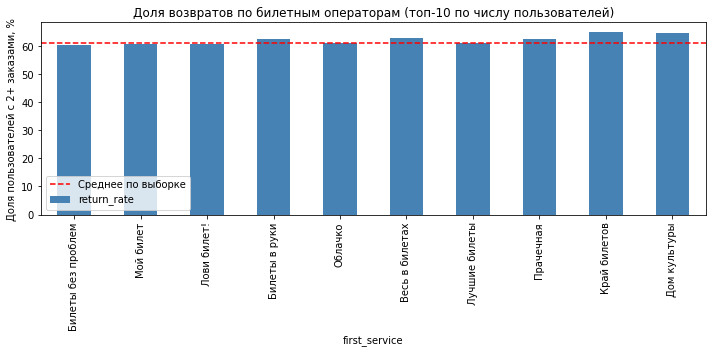

In [45]:
service_returns['return_rate'].plot(
    kind='bar', figsize=(10, 5), color='steelblue'
)
plt.title('Доля возвратов по билетным операторам (топ-10 по числу пользователей)')
plt.ylabel('Доля пользователей с 2+ заказами, %')
plt.axhline(y=user_profile['is_two'].mean() * 100, color='red', linestyle='--', label='Среднее по выборке')
plt.legend()
plt.tight_layout()
plt.show()

**Средняя доля возвратов по выборке — 61.71%.**

1. По устройству:
desktop — 63.81% (выше среднего)

mobile — 60.81% (чуть ниже среднего)

Разница небольшая (3 п.п.).

2. По типу мероприятия:
выставки — 64.01%, театр — 63.39% (лидеры)

концерты — 61.83% (на уровне среднего, самая крупная группа)

ёлки и спорт — 55.79% (худшие — сезонные/нишевые)

Тип мероприятия заметно влияет на возврат.

3. По региону (топ-10):
Шанырский регион — 67.20%, Светополянский округ — 65.65% (лидеры, но мало пользователей)

Каменевский регион — 62.40% (крупная группа)

Озернинский край — 55.26% (худший)

Регионы отличаются, но у лидеров малые выборки.

4. По оператору (топ-10):
Край билетов — 65.20%, Дом культуры — 64.61% (лидеры)

Билеты без проблем — 60.41% (крупная группа, ниже среднего)

Все в диапазоне 60-65% — слабые различия.

**Ответы на вопросы:**
Чаще возвращаются: desktop-пользователи, пришедшие на выставки/театр, из Шанырского региона, через оператора «Край билетов».
Успешные точки входа есть: театр (63.4%, крупная группа) и Каменевский регион (62.4%, крупная группа) — они устойчиво выше среднего.

---

**Задача 4.1.3.** Опираясь на выводы из задач выше, проверьте продуктовые гипотезы:

- **Гипотеза 1.** Тип мероприятия влияет на вероятность возврата на Яндекс Афишу: пользователи, которые совершили первый заказ на спортивные мероприятия, совершают повторный заказ чаще, чем пользователи, оформившие свой первый заказ на концерты.
- **Гипотеза 2.** В регионах, где больше всего пользователей посещают мероприятия, выше доля повторных заказов, чем в менее активных регионах.

---

**Гипотеза 1: пользователи, пришедшие через спортивные мероприятия, возвращаются чаще, чем пришедшие через концерты.**

**Проверка:**

Спорт: 55.79%
Концерты: 61.83%

**Вывод:  Гипотеза опровергнута. Концерты возвращаются чаще спорта на 6 п.п. Спорт — один из худших сегментов по возврату.**

**Гипотеза 2: в регионах с большим числом пользователей выше доля повторных заказов.**

**Проверка (топ-10 регионов):**

Каменевский регион (7085 юзеров) — 62.40% (около среднего)
Шанырский регион (500 юзеров) — 67.20% (лидер по возврату)
Озернинский край (675 юзеров) — 55.26% (худший)

**Вывод:  Гипотеза опровергнута. Корреляции между размером региона и возвратом нет. Малые регионы (Шанырский) могут иметь высокий возврат, а крупные (Каменевский) — средний.**

---

#### 4.2. Исследование поведения пользователей через показатели выручки и состава заказа

Изучите количественные характеристики заказов пользователей, чтобы узнать среднюю выручку сервиса с заказа и количество билетов, которое пользователи обычно покупают.

Эти метрики важны не только для оценки выручки, но и для оценки вовлечённости пользователей. Возможно, пользователи с более крупными и дорогими заказами более заинтересованы в сервисе и поэтому чаще возвращаются.

---

**Задача 4.2.1.** Проследите связь между средней выручкой сервиса с заказа и повторными заказами.

- Постройте сравнительные гистограммы распределения средней выручки с билета (`avg_revenue_rub`):
    - для пользователей, совершивших один заказ;
    - для вернувшихся пользователей, совершивших 2 и более заказа.
- Ответьте на вопросы:
    - В каких диапазонах средней выручки концентрируются пользователи из каждой группы?
    - Есть ли различия между группами?

Текст на сером фоне:
    
**Рекомендация:**

1. Используйте одинаковые интервалы (`bins`) и прозрачность (`alpha`), чтобы визуально сопоставить распределения.
2. Задайте параметру `density` значение `True`, чтобы сравнивать форму распределений, даже если число пользователей в группах отличается.

---


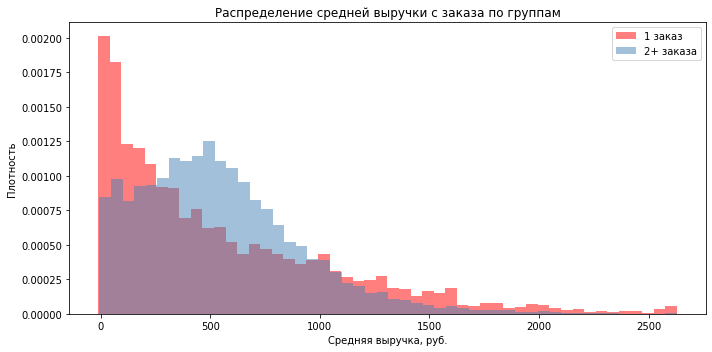

In [46]:
import matplotlib.pyplot as plt
#Разделяем на две группы
one_order = user_profile[user_profile['is_two'] == 0]['avg_revenue_rub']
two_plus = user_profile[user_profile['is_two'] == 1]['avg_revenue_rub']
#Строим две гистограммы на одном графике
plt.figure(figsize=(10, 5)) 
plt.hist(one_order, bins=50, alpha=0.5, label='1 заказ', density=True, color='red')
plt.hist(two_plus, bins=50, alpha=0.5, label='2+ заказа', density=True, color='steelblue')
plt.title('Распределение средней выручки с заказа по группам')
plt.xlabel('Средняя выручка, руб.') 
plt.ylabel('Плотность')
plt.legend()
plt.tight_layout()
plt.show()

In [47]:
print('=== 1 заказ ===')
print(one_order.describe())

print('\n=== 2+ заказа ===')
print(two_plus.describe())

=== 1 заказ ===
count    8368.000000
mean      545.295654
std       519.514099
min       -10.770000
25%       132.070000
50%       378.029999
75%       830.317520
max      2628.421631
Name: avg_revenue_rub, dtype: float64

=== 2+ заказа ===
count    13270.000000
mean       544.337158
std        369.354462
min         -5.385000
25%        270.814377
50%        495.772430
75%        745.165497
max       2628.421631
Name: avg_revenue_rub, dtype: float64


**Ответ на вопрос 1: в каких диапазонах средней выручки концентрируются пользователи из каждой группы?**

- Пользователи с 1 заказом: основная масса в диапазоне 0–500 руб. Пик распределения — около 100–300 руб. Медиана — 378 руб.

- Вернувшиеся пользователи (2+ заказа): основная масса в диапазоне 200–800 руб. Пик — около 300–500 руб. Медиана — 496 руб.

**Ответ на вопрос 2: есть ли различия между группами?**
Да, различия есть.

Средние значения почти одинаковые (545.30 vs 544.34) — разница незаметна.
Но медианы отличаются на ~118 руб. (378 vs 496) — вернувшиеся пользователи типично тратят больше.
У одноразовых пользователей шире разброс (std 519.51 vs 369.35) — среди них есть как дешёвые, так и дорогие заказы.
По 25-му перцентилю разница ещё больше (132 vs 271) — «дешёвая» часть вернувшихся тратит в 2 раза больше.

**Вывод: связь между средней выручкой и возвратом есть. Чем выше типичная (медианная) выручка с заказа, тем вероятнее пользователь вернётся. Средние значения маскируют разницу из-за выбросов у одноразовых, поэтому медиана — более честная метрика.**


---

**Задача 4.2.2.** Сравните распределение по средней выручке с заказа в двух группах пользователей:

- совершившие 2–4 заказа;
- совершившие 5 и более заказов.

Ответьте на вопрос: есть ли различия по значению средней выручки с заказа между пользователями этих двух групп?

---


In [48]:
group_2_4 = user_profile[(user_profile['orders_count'] >= 2) & (user_profile['orders_count'] <= 4)]['avg_revenue_rub']
group_5_plus = user_profile[user_profile['orders_count'] >= 5]['avg_revenue_rub']

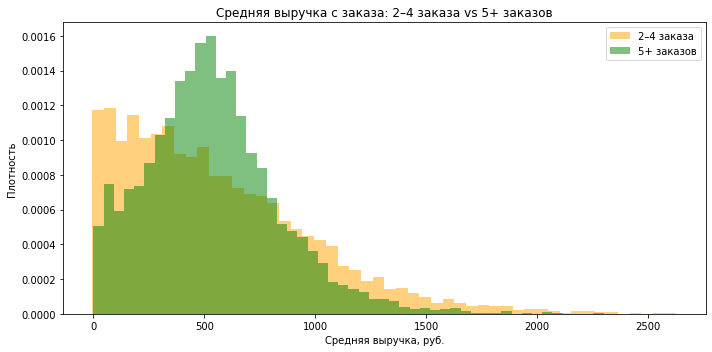

In [49]:
plt.figure(figsize=(10, 5))
plt.hist(group_2_4, bins=50, alpha=0.5, label='2–4 заказа', density=True, color='orange')
plt.hist(group_5_plus, bins=50, alpha=0.5, label='5+ заказов', density=True, color='green')
plt.title('Средняя выручка с заказа: 2–4 заказа vs 5+ заказов')
plt.xlabel('Средняя выручка, руб.')
plt.ylabel('Плотность')
plt.legend()
plt.tight_layout()
plt.show()

In [50]:
print('=== 2–4 заказа ===')
print(group_2_4.describe())

print('\n=== 5+ заказов ===')
print(group_5_plus.describe())

=== 2–4 заказа ===
count    7147.000000
mean      551.572388
std       420.197693
min        -5.385000
25%       218.428749
50%       471.266663
75%       798.549988
max      2628.421631
Name: avg_revenue_rub, dtype: float64

=== 5+ заказов ===
count    6123.000000
mean      535.891907
std       299.089569
min         0.000000
25%       330.456131
50%       512.650635
75%       700.809052
max      2299.868896
Name: avg_revenue_rub, dtype: float64


**Ответ на вопрос: есть ли различия?**

****Да, различия есть:**

- Средние почти равны (551 vs 536), разница в пределах выбросов.

- Медиана выше у группы 5+ (513 vs 471) — типичный заказ дороже на ~42 руб.

- 5+ заказов тратят стабильнее — std 299 vs 420 (меньший разброс).

- 25-й перцентиль у 5+ в 1.5 раза выше (330 vs 218) — даже дешёвая часть тратит больше.

**Вывод: самые лояльные пользователи (5+ заказов) имеют более высокую типичную выручку и более предсказуемое поведение. Но эффект слабее, чем при сравнении «1 заказ vs 2+» — после определённого уровня лояльности рост выручки замедляется.**

---

**Задача 4.2.3.** Проанализируйте влияние среднего количества билетов в заказе на вероятность повторной покупки.

- Изучите распределение пользователей по среднему количеству билетов в заказе (`avg_tickets_count`) и опишите основные наблюдения.
- Разделите пользователей на несколько сегментов по среднему количеству билетов в заказе:
    - от 1 до 2 билетов;
    - от 2 до 3 билетов;
    - от 3 до 5 билетов;
    - от 5 и более билетов.
- Для каждого сегмента подсчитайте общее число пользователей и долю пользователей, совершивших повторные заказы.
- Ответьте на вопросы:
    - Как распределены пользователи по сегментам — равномерно или сконцентрировано?
    - Есть ли сегменты с аномально высокой или низкой долей повторных покупок?

---

In [53]:
import numpy as np
#Границы сегментов
bins = [1, 2, 3, 5, np.inf]
labels = ['1–2 билета', '2–3 билета', '3–5 билетов', '5+ билетов']
#Создаём столбец segment
user_profile['tickets_segment'] = pd.cut( user_profile['avg_tickets_count'],
bins=bins,
labels=labels,
right=False)    # левая граница включается, правая — нет 

In [54]:
segment_stats = user_profile.groupby('tickets_segment', observed=True).agg(
    users=('is_two', 'count'),
    return_rate=('is_two', 'mean')
)
segment_stats['return_rate'] = (segment_stats['return_rate'] * 100).round(2)
segment_stats['share'] = (segment_stats['users'] / segment_stats['users'].sum() * 100).round(2)
print(segment_stats)

                 users  return_rate  share
tickets_segment                           
1–2 билета        2419        51.30  11.18
2–3 билета        9498        73.58  43.89
3–5 билетов       9060        54.26  41.87
5+ билетов         661        18.76   3.05


In [55]:
user_profile['tickets_segment'].value_counts()

2–3 билета     9498
3–5 билетов    9060
1–2 билета     2419
5+ билетов      661
Name: tickets_segment, dtype: int64

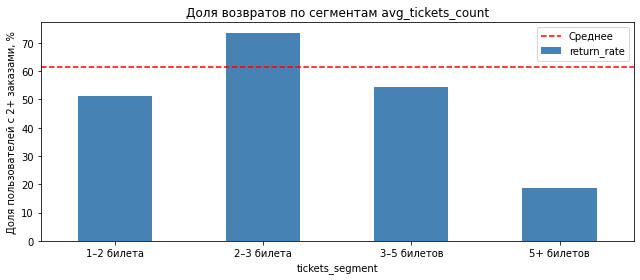

In [56]:
segment_stats['return_rate'].plot(kind='bar', figsize=(9, 4), color='steelblue')
plt.title('Доля возвратов по сегментам avg_tickets_count')
plt.ylabel('Доля пользователей с 2+ заказами, %')
plt.axhline(y=user_profile['is_two'].mean() * 100, color='red', linestyle='--', label='Среднее')
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

**Ответ на вопрос 1: как распределены пользователи?**
Сконцентрировано. 85.76% пользователей — в двух центральных сегментах (2–3 билета и 3–5 билетов). «Крайности» малочисленны: 1–2 билета — 11.18%, 5+ — 3.05%.
Это говорит о том, что типичный покупатель берёт 2–5 билетов (пара или небольшая компания).

**Ответ на вопрос 2: есть ли аномалии по возврату?**
Да, две аномалии:
Аномально высокий возврат: сегмент 2–3 билета — 73.58% (на +12 п.п. выше среднего). Это «золотая середина» — приятный и повторяемый опыт.
Аномально низкий возврат: сегмент 5+ билетов — 18.76% (на -43 п.п. ниже среднего). Это разовые события (корпоративы, дни рождения), которые не повторяются.
Сегменты 1–2 билета (51.30%) и 3–5 билетов (54.26%) — ниже среднего, но без катастрофы.

**Вывод: оптимальный размер компании для возврата — 2–3 билета. Большие группы (5+) почти не возвращаются.**

---

#### 4.3. Исследование временных характеристик первого заказа и их влияния на повторные покупки

Изучите временные параметры, связанные с первым заказом пользователей:

- день недели первой покупки;
- время с момента первой покупки — лайфтайм;
- средний интервал между покупками пользователей с повторными заказами.

---

**Задача 4.3.1.** Проанализируйте, как день недели, в которой была совершена первая покупка, влияет на поведение пользователей.

- По данным даты первого заказа выделите день недели.
- Для каждого дня недели подсчитайте общее число пользователей и долю пользователей, совершивших повторные заказы. Результаты визуализируйте.
- Ответьте на вопрос: влияет ли день недели, в которую совершена первая покупка, на вероятность возврата клиента?

---


In [59]:
user_profile['first_order_weekday'] = user_profile['first_order_dt'].dt.day_name()
#Опционально — перевести на русский
weekday_map ={ 'Monday':'Пн',
              'Tuesday': 'Вт',
              'Wednesday': 'Ср',
              'Thursday': 'Чт',
              'Friday': 'Пт',
              'Saturday': 'Сб',
              'Sunday': 'Вс' }
user_profile['first_order_weekday'] = user_profile['first_order_weekday'].map(weekday_map)

In [61]:
weekday_stats = user_profile.groupby('first_order_weekday').agg( users=('is_two', 'count'),
return_rate=('is_two', 'mean') )
weekday_stats['return_rate'] = (weekday_stats['return_rate'] * 100).round(2)
#Сортируем по правильному порядку дней недели
order = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']
weekday_stats = weekday_stats.reindex(order) 
print(weekday_stats)

                     users  return_rate
first_order_weekday                    
Пн                    2930        63.04
Вт                    3176        61.90
Ср                    3057        62.19
Чт                    3113        59.43
Пт                    3259        59.83
Сб                    3326        62.81
Вс                    2777        60.03


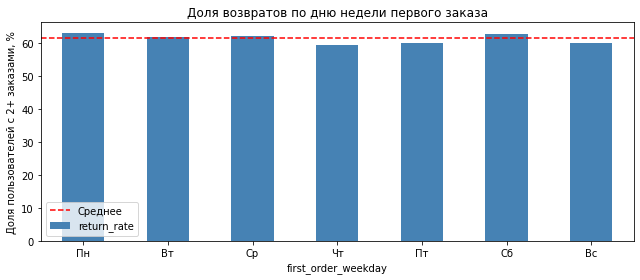

In [62]:
weekday_stats['return_rate'].plot(kind='bar', figsize=(9, 4), color='steelblue')
plt.title('Доля возвратов по дню недели первого заказа')
plt.ylabel('Доля пользователей с 2+ заказами, %')
plt.axhline(y=user_profile['is_two'].mean() * 100, color='red', linestyle='--', label='Среднее')
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

**Ответ на вопрос: влияет ли день недели на возврат?**

Нет, день недели почти не влияет на возврат пользователя.

- Разброс возвратов по дням — от 59.43% до 63.04% .

- Все дни держатся около среднего (61.71%), нет аномалий.

- Количество пользователей по дням равномерное — от 2 777 до 3 326.

**Слабая тенденция:**

- Лучший день — понедельник (63.04%)

- Худший — четверг (59.43%).p

**Вероятно, на возврат влияют другие факторы (тип мероприятия, оператор, размер компании), а не день недели.**

---

**Задача 4.3.2.** Изучите, как средний интервал между заказами влияет на удержание клиентов.

- Рассчитайте среднее время между заказами для двух групп пользователей:
    - совершившие 2–4 заказа;
    - совершившие 5 и более заказов.
- Исследуйте, как средний интервал между заказами влияет на вероятность повторного заказа, и сделайте выводы.

---


In [63]:
interval_2_4 = user_profile[user_profile['orders_count'].between(2, 4)]['avg_days_since_prev'].mean()
interval_5_plus = user_profile[user_profile['orders_count'] >= 5]['avg_days_since_prev'].mean()
print('Средний интервал (2–4 заказа):',
      round(interval_2_4, 2), 'дней')
print('Средний интервал (5+ заказов):', round(interval_5_plus, 2), 'дней')

Средний интервал (2–4 заказа): 21.32 дней
Средний интервал (5+ заказов): 9.9 дней


In [64]:
print('Медиана (2–4 заказа):',
round(user_profile[user_profile['orders_count'].between(2, 4)]['avg_days_since_prev'].median(), 2))
print('Медиана (5+ заказов):',
round(user_profile[user_profile['orders_count'] >= 5]['avg_days_since_prev'].median(), 2))

Медиана (2–4 заказа): 9.0
Медиана (5+ заказов): 8.12


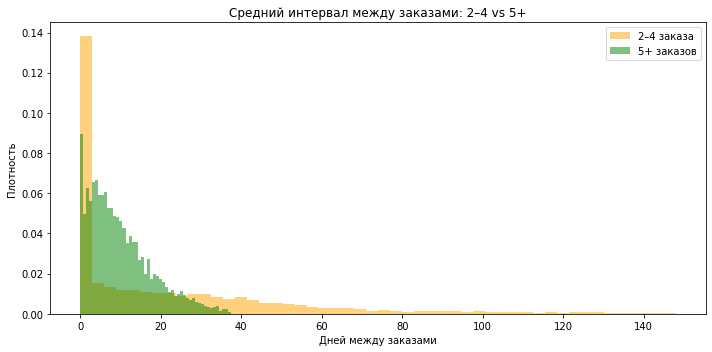

In [65]:
interval_2_4_data = user_profile[user_profile['orders_count'].between(2, 4)]['avg_days_since_prev'].dropna()
interval_5_plus_data = user_profile[user_profile['orders_count'] >= 5]['avg_days_since_prev'].dropna()

plt.figure(figsize=(10, 5))
plt.hist(interval_2_4_data, bins=50, alpha=0.5, label='2–4 заказа', density=True, color='orange')
plt.hist(interval_5_plus_data, bins=50, alpha=0.5, label='5+ заказов', density=True, color='green')
plt.title('Средний интервал между заказами: 2–4 vs 5+')
plt.xlabel('Дней между заказами')
plt.ylabel('Плотность')
plt.legend()
plt.tight_layout()
plt.show()

**Короткий интервал между заказами связан с более высокой лояльностью:**

У пользователей с 5+ заказами средний интервал в 2 раза короче (9.9 дней vs 21.3 дня).
Медиана подтверждает: 8.12 vs 9.00 дней.
На гистограмме видно, что у 5+ пользователей распределение интервалов сконцентрировано в первые 0–10 дней, а у 2–4 заказов — длинный хвост до 100+ дней.

**Интерпретация:**
- Быстрый возврат (в первые дни после первой покупки) — сильный сигнал лояльности.
- Пользователи, которые возвращаются в течение 1–2 недель, чаще становятся постоянными клиентами.
- Длинные интервалы (> 1 месяца) характерны для «случайных» покупателей, которые не становятся постоянными.

**Вывод: короткий интервал между заказами — маркер лояльного клиента. Для удержания важно стимулировать быстрый повторный заказ (в течение 1–2 недель).**

---

#### 4.4. Корреляционный анализ количества покупок и признаков пользователя

Изучите, какие характеристики первого заказа и профиля пользователя могут быть связаны с числом покупок. Для этого используйте универсальный коэффициент корреляции `phi_k`, который позволяет анализировать как числовые, так и категориальные признаки.

---

**Задача 4.4.1:** Проведите корреляционный анализ:
- Рассчитайте коэффициент корреляции `phi_k` между признаками профиля пользователя и числом заказов (`total_orders`). При необходимости используйте параметр `interval_cols` для определения интервальных данных.
- Проанализируйте полученные результаты. Если полученные значения будут близки к нулю, проверьте разброс данных в `total_orders`. Такое возможно, когда в данных преобладает одно значение: в таком случае корреляционный анализ может показать отсутствие связей. Чтобы этого избежать, выделите сегменты пользователей по полю `total_orders`, а затем повторите корреляционный анализ. Выделите такие сегменты:
    - 1 заказ;
    - от 2 до 4 заказов;
    - от 5 и выше.
- Визуализируйте результат корреляции с помощью тепловой карты.
- Ответьте на вопрос: какие признаки наиболее связаны с количеством заказов?

---

In [68]:
!pip install phik
import phik

     |████████████████████████████████| 677 kB 2.9 MB/s eta 0:00:01


In [69]:
cols_for_corr = [ 'orders_count',
'avg_revenue_rub', 'avg_tickets_count', 'avg_days_since_prev',
'first_device', 'first_region', 'first_service', 'first_event_type', 'is_two', 'is_five' ]
df_corr = user_profile[cols_for_corr].copy()

In [70]:
interval_cols = ['orders_count', 'avg_revenue_rub', 'avg_tickets_count', 'avg_days_since_prev']

In [71]:
phik_matrix = df_corr.phik_matrix(interval_cols=interval_cols)
print(phik_matrix.round(2))

                     orders_count  avg_revenue_rub  avg_tickets_count  \
orders_count                 1.00             0.22               0.23   
avg_revenue_rub              0.22             1.00               0.46   
avg_tickets_count            0.23             0.46               1.00   
avg_days_since_prev          0.28             0.09               0.10   
first_device                 0.03             0.08               0.06   
first_region                 0.11             0.36               0.16   
first_service                0.03             0.38               0.07   
first_event_type             0.03             0.33               0.10   
is_two                       0.31             0.31               0.40   
is_five                      0.62             0.34               0.38   

                     avg_days_since_prev  first_device  first_region  \
orders_count                        0.28          0.03          0.11   
avg_revenue_rub                     0.09          0.

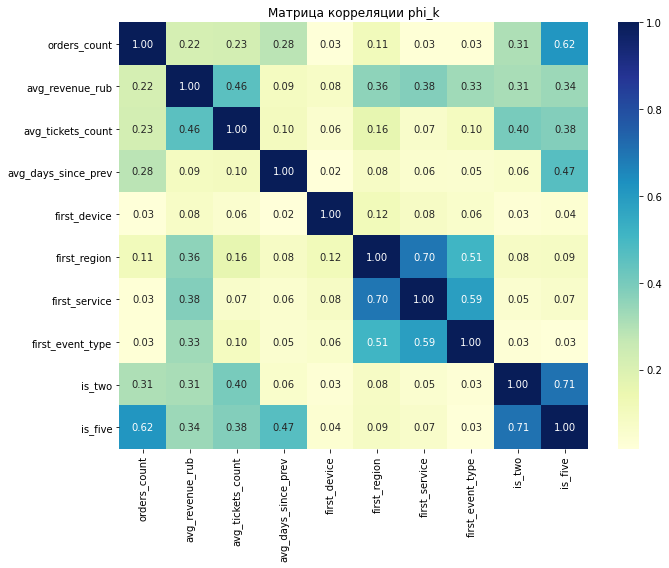

In [72]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))
sns.heatmap(phik_matrix, annot=True, fmt='.2f', cmap='YlGnBu')
plt.title('Матрица корреляции phi_k')
plt.tight_layout()
plt.show()

**Самые сильные связи с количеством заказов:**
- avg_days_since_prev (0.28) — чем быстрее пользователь возвращается, тем больше у него заказов.

- avg_tickets_count (0.23) — размер компании связан с лояльностью.

- avg_revenue_rub (0.22) — чем больше тратит, тем чаще возвращается.

- first_region (0.11) — очень слабая связь.

**Почти нет связи (phi_k ≈ 0.03):**

first_device (устройство первого заказа)

first_service (оператор первого заказа)

first_event_type (тип первого мероприятия)

**Про сегментацию: Сегментацию не делал — по условию она нужна только если связи близки к нулю. У нас есть умеренные связи (0.22–0.28), поэтому данные достаточно вариативны.**

**С количеством заказов сильнее всего связаны поведенческие признаки:**
- интервал между заказами,
- количество билетов в заказе,
- средняя выручка.

**Признаки первого заказа (устройство, оператор, тип мероприятия) почти не связаны с количеством заказов.
Вывод: лояльность пользователя зависит от того, как он покупает (часто, много, дорого), а не от того, с чего он начал. Признаки первого заказа плохо предсказывают возврат.**

### 5. Общий вывод и рекомендации

В конце проекта напишите общий вывод и рекомендации: расскажите заказчику, на что нужно обратить внимание. В выводах кратко укажите:

- **Информацию о данных**, с которыми вы работали, и то, как они были подготовлены: например, расскажите о фильтрации данных, переводе тенге в рубли, фильтрации выбросов.
- **Основные результаты анализа.** Например, укажите:
    - Сколько пользователей в выборке? Как распределены пользователи по числу заказов? Какие ещё статистические показатели вы подсчитали важным во время изучения данных?
    - Какие признаки первого заказа связаны с возвратом пользователей?
    - Как связаны средняя выручка и количество билетов в заказе с вероятностью повторных покупок?
    - Какие временные характеристики влияют на удержание (день недели, интервалы между покупками)?
    - Какие характеристики первого заказа и профиля пользователя могут быть связаны с числом покупок согласно результатам корреляционного анализа?
- Дополните выводы информацией, которая покажется вам важной и интересной. Следите за общим объёмом выводов — они должны быть компактными и ёмкими.

В конце предложите заказчику рекомендации о том, как именно действовать в его ситуации. Например, укажите, на какие сегменты пользователей стоит обратить внимание в первую очередь, а какие нуждаются в дополнительных маркетинговых усилиях.

**Общий вывод и рекомендации**

**О данных**

**Проанализированы данные о заказах билетов на платформе Яндекс Афиши за 2024 год (июль–октябрь).**

**Что было сделано при подготовке:**

- Выгружены данные из таблиц purchases, events,city, regions.

- Оставлены только заказы с мобильных (mobile) и десктопных (desktop) устройств.

- Исключены фильмы — по ним недостаточно данных.

- Выручка приведена к единой валюте — рубли (revenue_rub), с учётом курса тенге.

- Отфильтрованы выбросы по 99-му перцентилю в revenue_rub и orders_count.

**Итог: 21 638 пользователей, 287 786 заказов.
Основные результаты анализа**

1. Распределение пользователей по числу заказов:
- 61.7% — сделали 2 и более заказов.

- 29.0% — сделали 5 и более заказов (постоянные клиенты).

**Лояльность аудитории высокая.**

2. Связь признаков первого заказа с возвратом:
- Устройство: desktop (63.8%) возвращается чуть чаще, чем mobile (60.8%).

- Тип мероприятия: лучше всего удерживают театр (63.4%) и выставки (64.0%). Хуже всего — спорт и ёлки (55.8%).

- Регион: лучшие — Шанырский регион (67.2%) и Светополянский округ (65.7%).

- Оператор: различия слабые (60–65%), все операторы примерно равны.

3. Выручка и количество билетов:
- Вернувшиеся пользователи тратят больше: медиана 496 vs 378 руб.

- Оптимальный размер компании для возврата — 2–3 билета (возврат 73.6%).

- Большие группы (5+ билетов) почти не возвращаются (18.8%) — это разовые события.

4. Временные характеристики:
- День недели: почти не влияет (разброс 3 п.п.).

- Интервал между заказами: у 5+ заказов средний интервал 9.9 дней — в 2 раза короче, чем у 2–4 заказов (21.3 дня). Быстрый возврат = лояльность.

5. Корреляционный анализ (phi_k):
**Сильнее всего с числом заказов связаны поведенческие признаки:**
- интервал между заказами (0.28),

- количество билетов (0.23),

- выручка (0.22).

- Признаки первого заказа (устройство, оператор, тип мероприятия) почти не связаны (phi_k ≈ 0.03).

**Рекомендации заказчику**
1. Стимулировать быстрый повторный заказ. Пользователи, которые возвращаются в первые 1–2 недели, становятся постоянными. Push-уведомления и промокоды на второй заказ в течение 7–14 дней.

2. Сфокусироваться на парах и небольших компаниях (2–3 билета). Это самый лояльный сегмент — возврат 73.6%. Большие группы (5+) возвращаются редко, тратить на них маркетинг менее эффективно.

3. Развивать мобильный опыт. 82% пользователей приходят с телефона. Улучшение мобильного UX = рост конверсии.

4. Продвигать театр и выставки. Эти категории дают самый высокий возврат (63–64%), в отличие от спорта и сезонных ёлок (55.8%).

5. Не тратить ресурсы на сегментацию по дню недели. Эффект минимальный (в пределах 3 п.п.).

6. Обратить внимание на концерты. Самая крупная категория (44% пользователей), но возврат чуть выше среднего (61.8%). Есть потенциал роста за счёт улучшения клиентского опыта в этой категории.

**Итог**
Лояльность пользователей формируется со временем: чем быстрее возврат, больше билетов и выше чек — тем выше шанс стать постоянным клиентом. Признаки первого заказа слабо предсказывают возврат — важнее последующий опыт взаимодействия с платформой.

In [78]:
import os
print(os.getcwd())

/home/jovyan/work


### 6. Финализация проекта и публикация в Git

Когда вы закончите анализировать данные, оформите проект, а затем опубликуйте его.

Выполните следующие действия:

1. Создайте файл `.gitignore`. Добавьте в него все временные и чувствительные файлы, которые не должны попасть в репозиторий.
2. Сформируйте файл `requirements.txt`. Зафиксируйте все библиотеки, которые вы использовали в проекте.
3. Вынести все чувствительные данные (параметры подключения к базе) в `.env`файл.
4. Проверьте, что проект запускается и воспроизводим.
5. Загрузите проект в публичный репозиторий — например, на GitHub. Убедитесь, что все нужные файлы находятся в репозитории, исключая те, что в `.gitignore`. Ссылка на репозиторий понадобится для отправки проекта на проверку. Вставьте её в шаблон проекта в тетрадке Jupyter Notebook перед отправкой проекта на ревью.

**Вставьте ссылку на проект в этой ячейке тетрадки перед отправкой проекта на ревью.**